--- Loading Dataset ---
Dataset loaded successfully!

--- Data Understanding ---


,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.16,151266



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12294 entries, 0 to 12293
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   anime_id  12294 non-null  int64  
 1   name      12294 non-null  object 
 2   genre     12232 non-null  object 
 3   type      12269 non-null  object 
 4   episodes  12294 non-null  object 
 5   rating    12064 non-null  float64
 6   members   12294 non-null  int64  
dtypes: float64(1), int64(2), object(4)
memory usage: 672.5+ KB

Statistical Summary:


,anime_id,rating,members
count,12294.000000,12064.000000,1.229400e+04
mean,14058.221653,6.473902,1.807134e+04
std,11455.294701,1.026746,5.482068e+04
min,1.000000,1.670000,5.000000e+00
25%,3484.250000,5.880000,2.250000e+02
50%,10260.500000,6.570000,1.550000e+03
75%,24794.500000,7.180000,9.437000e+03
max,34527.000000,10.000000,1.013917e+06



--- Data Transformation ---


,name,genre,type,episodes,rating,members,members_in_k
0,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1.0,9.37,200630,200.630
1,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64.0,9.26,793665,793.665
2,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51.0,9.25,114262,114.262
3,Steins;Gate,"Sci-Fi, Thriller",TV,24.0,9.17,673572,673.572
4,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51.0,9.16,151266,151.266



--- Handling Null Values ---
Missing values BEFORE imputation:
name              0
genre            62
type             25
episodes        340
rating          230
members           0
members_in_k      0
dtype: int64

Missing values AFTER mean imputation:
name             0
genre           62
type            25
episodes         0
rating           0
members          0
members_in_k     0
dtype: int64

--- Insight Generation ---
Average Rating by Type:
 type
TV         6.889177
Special    6.523353
OVA        6.375996
Movie      6.321443
ONA        5.652120
Music      5.588996
Name: rating, dtype: float64

Top 5 Most Popular Genre Combinations:
 genre
Hentai                                                2046501
Comedy, School, Slice of Life                         1886851
Comedy, Slice of Life                                 1704120
Action, Adventure, Fantasy, Game, Romance             1603658
Action, Comedy, Martial Arts, Shounen, Super Power    1538128
Name: members, dtype: int64


/tmp/ipykernel_1950/790198996.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=type_rating.index, y=type_rating.values, ax=axes[0], palette="magma")


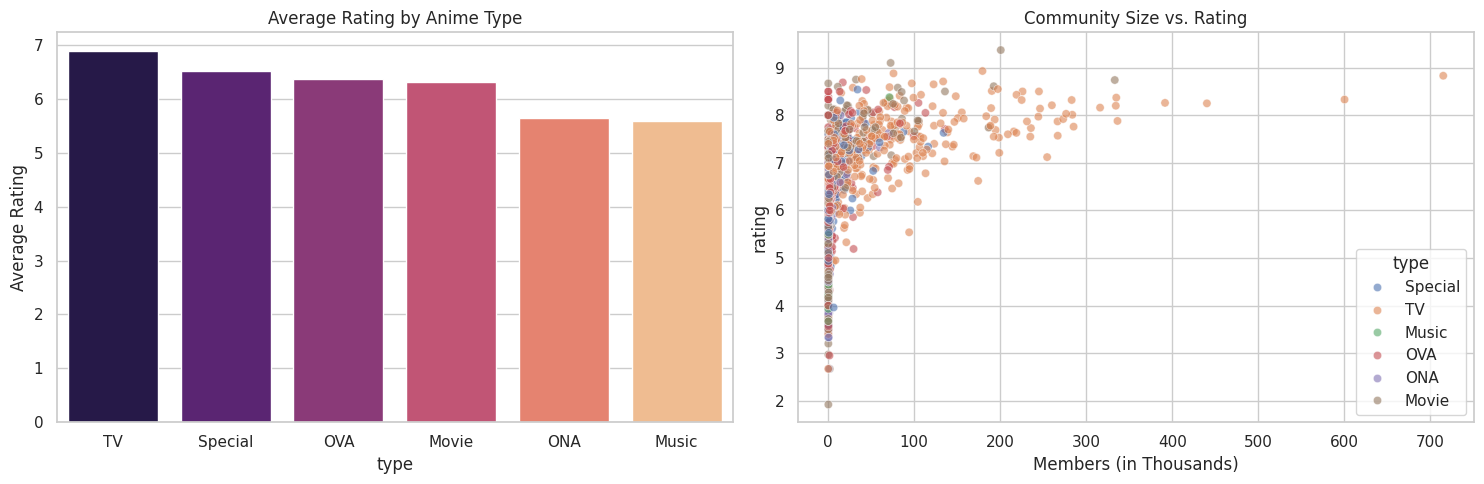

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. Dataset Selection and Reading
# ==========================================
print("--- Loading Dataset ---")
df = pd.read_csv('anime.csv')
print("Dataset loaded successfully!\n")

# ==========================================
# 2. Data Understanding
# ==========================================
print("--- Data Understanding ---")
display(df.head())

print("\nDataset Info:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

# ==========================================
# 3. Data Transformation
# ==========================================
print("\n--- Data Transformation ---")
# Drop the 'anime_id' column
df = df.drop(columns=['anime_id'])

# Convert 'episodes' to numeric, turning 'Unknown' strings into NaN
df['episodes'] = pd.to_numeric(df['episodes'], errors='coerce')

# Add a derived column for community members in thousands
df['members_in_k'] = df['members'] / 1000

display(df.head())

# ==========================================
# 4. Handling Null Values (Mean Imputation)
# ==========================================
print("\n--- Handling Null Values ---")
print("Missing values BEFORE imputation:")
print(df.isnull().sum())

# Impute missing values with column means
df['rating'] = df['rating'].fillna(df['rating'].mean())
df['episodes'] = df['episodes'].fillna(df['episodes'].mean())

print("\nMissing values AFTER mean imputation:")
print(df.isnull().sum())

# ==========================================
# 5. Insight Generation
# ==========================================
print("\n--- Insight Generation ---")
# Insight 1: Average Rating by Anime Format (TV, Movie, OVA, etc.)
type_rating = df.groupby('type')['rating'].mean().sort_values(ascending=False)
print("Average Rating by Type:\n", type_rating)

# Insight 2: Top 5 Genres by Total Community Members
top_genres = df.groupby('genre')['members'].sum().sort_values(ascending=False).head(5)
print("\nTop 5 Most Popular Genre Combinations:\n", top_genres)

# ==========================================
# 6. Data Visualization
# ==========================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Visualization 1: Average Rating by Type
sns.barplot(x=type_rating.index, y=type_rating.values, ax=axes[0], palette="magma")
axes[0].set_title('Average Rating by Anime Type')
axes[0].set_ylabel('Average Rating')

# Visualization 2: Members vs. Rating
sns.scatterplot(data=df.sample(2000, random_state=42), x='members_in_k', y='rating', hue='type', alpha=0.6, ax=axes[1])
axes[1].set_title('Community Size vs. Rating')
axes[1].set_xlabel('Members (in Thousands)')

plt.tight_layout()
plt.show()